# 6. Interpretabilidad con LIME

Sección 5.5 del enunciado. Se explica el modelo con mayor AUC de cada entorno **entre los
que entregan probabilidades** (LinearSVC queda excluido) sobre dos instancias de test
**mal clasificadas por ambos modelos**: un falso negativo y un falso positivo (con el umbral
elegido en train).

**Espacio de explicación.** LIME perturba las variables *originales* (antes de escalar y
codificar) para que las explicaciones sean legibles: montos en dólares, tasa en %,
categorías con su nombre. La función de predicción aplica internamente el preprocesamiento
ajustado con train y luego el modelo. En `mths_since_last_delinq`, `emp_length_anios` y
`mort_acc` el valor −1 representa "dato faltante" (informativo según el EDA) y se
reconvierte a nulo antes de predecir.

**Explicaciones de PySpark.** Se generaron al final del notebook 04, con el modelo ganador
todavía vivo en la sesión de Spark (ver allí la justificación). Aquí se cargan y se
comparan con las de scikit-learn, calculadas con el **mismo explicador, las mismas
instancias y la misma semilla** (por tanto, las mismas 2.000 perturbaciones).

In [1]:
import sys  # Permite modificar la ruta de búsqueda de módulos
sys.path.insert(0, "..")  # Agrega la raíz del proyecto
import time  # Medición de tiempos
import joblib  # Carga del modelo y de los transformadores de scikit-learn
import numpy as np  # Cálculo numérico
import pandas as pd  # Manipulación de datos
import matplotlib.pyplot as plt  # Gráficos
from IPython.display import Image, display  # Muestra figuras guardadas
from src import config as cfg  # Configuración central
from src import lime_utils  # Utilidades de LIME compartidas con el notebook 04
from src import preparacion as prep  # Transformaciones con pandas
from src.utilidades import guardar_figura, leer_json  # Utilidades

lime_sp = leer_json(lime_utils.RUTA_EXPLICACIONES_SP)  # Explicaciones de PySpark (notebook 04)
met_sk = leer_json(cfg.RUTA_METRICAS_SK)["modelos"]  # Métricas de scikit-learn
met_sp = leer_json(cfg.RUTA_METRICAS_SP)["modelos"]  # Métricas de PySpark
mejor_sk, mejor_sp = lime_sp["mejor_sklearn"], lime_sp["mejor_pyspark"]  # Modelos explicados
instancias = lime_sp["instancias"]  # Instancias elegidas en el notebook 04
print(f"scikit-learn → {mejor_sk} (AUC {met_sk[mejor_sk]['metricas']['roc_auc']:.4f}, umbral {met_sk[mejor_sk]['umbral']:.3f})")  # Modelo elegido
print(f"PySpark      → {mejor_sp} (AUC {met_sp[mejor_sp]['metricas']['roc_auc']:.4f}, umbral {met_sp[mejor_sp]['umbral']:.3f})")  # Modelo elegido
print(f"Falsos negativos comunes: {lime_sp['n_fn_comunes']:,} | falsos positivos comunes: {lime_sp['n_fp_comunes']:,}")  # Tamaño de cada grupo
print("Instancias explicadas:", instancias)  # Identificadores

scikit-learn → GradientBoosting (AUC 0.7207, umbral 0.215)
PySpark      → GradientBoosting (AUC 0.7208, umbral 0.214)
Falsos negativos comunes: 18,480 | falsos positivos comunes: 62,896
Instancias explicadas: {'Falso negativo': 101230150, 'Falso positivo': 2826869}


## Función de predicción de scikit-learn

In [2]:
espacio = lime_utils.EspacioLime()  # Datos en el espacio original y conversiones
tr = joblib.load(cfg.DIR_SKLEARN_PREP / "transformadores.joblib")  # Transformadores ajustados con train (notebook 02)
modelo_sk = joblib.load(cfg.DIR_MODELOS_SK / f"{mejor_sk}.joblib")  # Mejor modelo de scikit-learn (notebook 03)


def predecir_sk(X):  # Función de predicción que LIME llamará con cada lote de perturbaciones
    d = prep.transformar_numericas(espacio.desde_lime(X))  # Espacio original + log1p + indicadores de nulo
    num = tr["escalador"].transform(tr["imputador"].transform(d[tr["numericas"]]))  # Imputa y escala con parámetros de train
    cat = tr["codificador"].transform(d[cfg.CATEGORICAS_MODELO])  # One-hot con las categorías de train
    return modelo_sk.predict_proba(np.hstack([num, cat]).astype(np.float32))  # Probabilidades [P(0), P(1)]


verif = predecir_sk(espacio.a_lime(espacio.test.iloc[:2000]))[:, 1]  # Verificación sobre 2.000 filas de test
guardadas = pd.read_parquet(cfg.DIR_SCORES_SK / f"{mejor_sk}.parquet").set_index(cfg.COL_ID).loc[espacio.test[cfg.COL_ID].iloc[:2000], "score"].to_numpy()  # Puntuaciones del notebook 03
print(f"Máx. diferencia con las puntuaciones del notebook 03: {np.abs(verif - guardadas).max():.2e}")  # ≈ 0

Máx. diferencia con las puntuaciones del notebook 03: 0.00e+00


C:\Users\user-pc\.conda\envs\ml_venv\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\user-pc\.conda\envs\ml_venv\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\Users\user-pc\.conda\envs\ml_venv\lib\subprocess.py", line 505, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Users\user-pc\.conda\envs\ml_venv\lib\subprocess.py", line 951, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\user-pc\.conda\envs\ml_venv\lib\subprocess.py", line 1436, in _execute_child
    hp, ht, pid, tid = _winapi.Create

## Instancias explicadas (valores originales)

In [3]:
t = espacio.test.set_index(cfg.COL_ID).loc[list(instancias.values()), lime_utils.VARIABLES + [cfg.COL_TARGET]].T  # Valores originales
t.columns = [f"{k} (id {v})" for k, v in instancias.items()]  # Encabezados descriptivos
t  # Muestra la tabla

,Falso negativo (id 101230150),Falso positivo (id 2826869)
loan_amnt,15775.0,9750.0
term_meses,36.0,36.0
int_rate,11.49,17.77
annual_inc,65000.0,30000.0
dti,19.43,20.92
fico_range_high,704.0,679.0
emp_length_anios,0.0,5.0
delinq_2yrs,0.0,0.0
inq_last_6mths,0.0,1.0
open_acc,29.0,8.0


## Explicaciones locales de scikit-learn

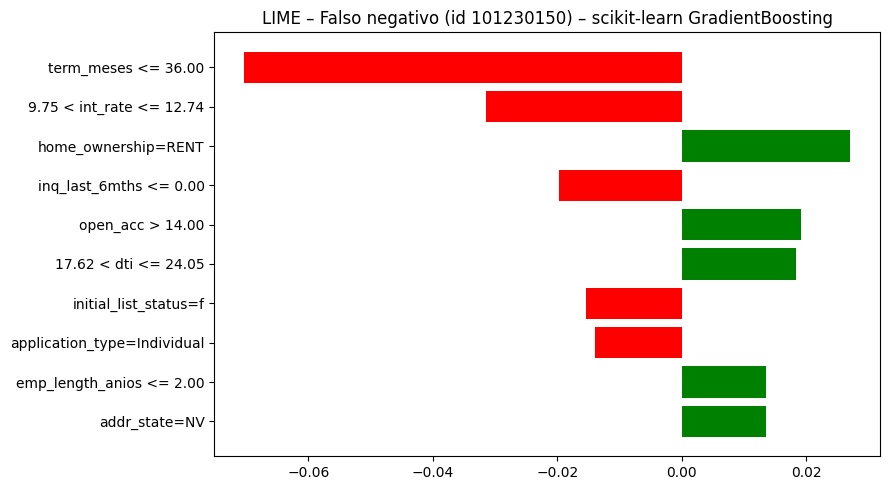

Falso negativo: P(default)=0.156  R² local=0.175  tiempo=3.53s


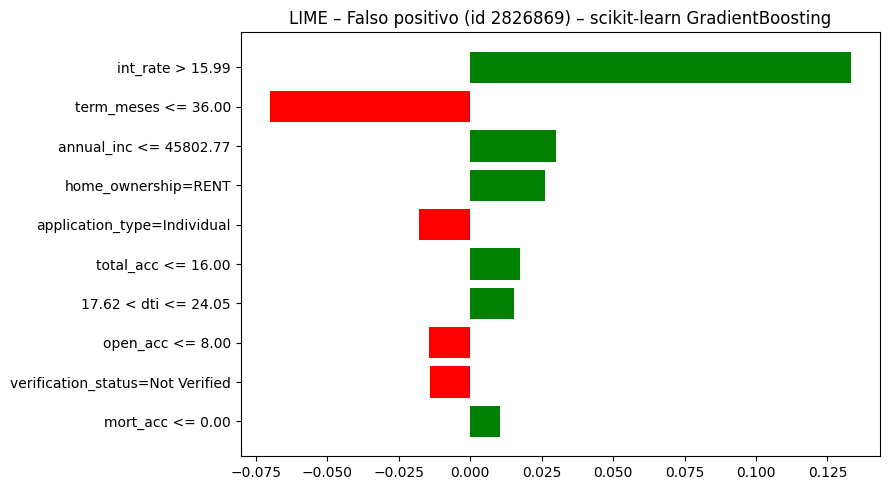

Falso positivo: P(default)=0.341  R² local=0.525  tiempo=3.49s


In [4]:
explicaciones_sk = {}  # Explicaciones de scikit-learn por instancia
for etiqueta, id_ in instancias.items():  # Recorre las dos instancias
    t0 = time.time()  # Inicio de la explicación
    exp = espacio.explicador().explain_instance(espacio.instancia(id_), predecir_sk, num_features=lime_utils.N_VARIABLES, num_samples=lime_utils.N_MUESTRAS)  # Explicación local
    explicaciones_sk[etiqueta] = {"exp": exp, "tiempo_s": time.time() - t0}  # Guarda la explicación y el tiempo
    fig = exp.as_pyplot_figure(label=1); fig.set_size_inches(9, 5)  # Pesos hacia "Charged Off"
    plt.title(f"LIME – {etiqueta} (id {id_}) – scikit-learn {mejor_sk}"); plt.tight_layout()  # Título
    guardar_figura(fig, f"06_lime_{etiqueta.replace(' ', '_')}_sklearn"); plt.show()  # Exporta y muestra
    print(f"{etiqueta}: P(default)={exp.predict_proba[1]:.3f}  R² local={exp.score:.3f}  tiempo={time.time() - t0:.2f}s")  # Resumen

In [5]:
for etiqueta in instancias:  # Visualización HTML interactiva de LIME (valores + contribuciones)
    print(f"{etiqueta} – scikit-learn")  # Encabezado
    explicaciones_sk[etiqueta]["exp"].show_in_notebook(show_table=True)  # Tabla y barras de LIME

Falso negativo – scikit-learn


Falso positivo – scikit-learn


## Explicaciones locales de PySpark (generadas en el notebook 04)

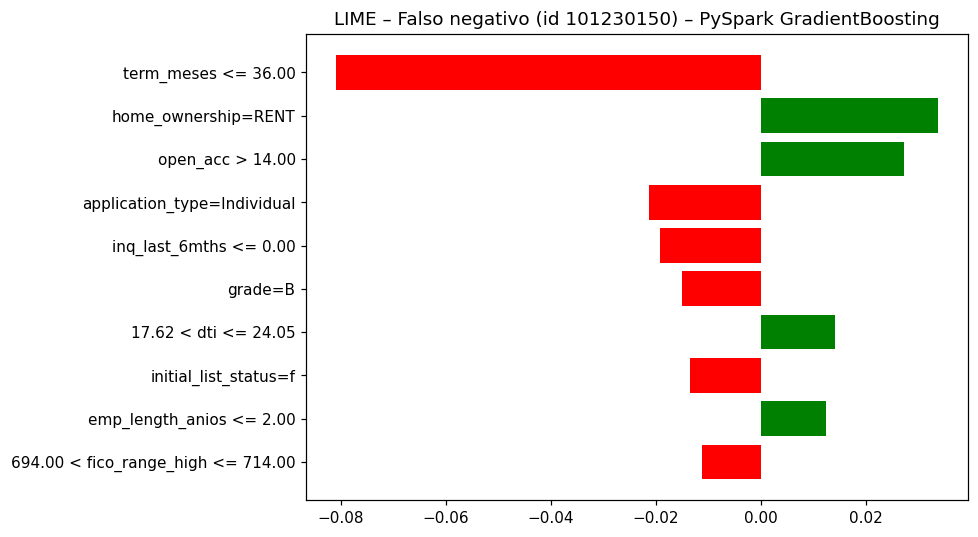

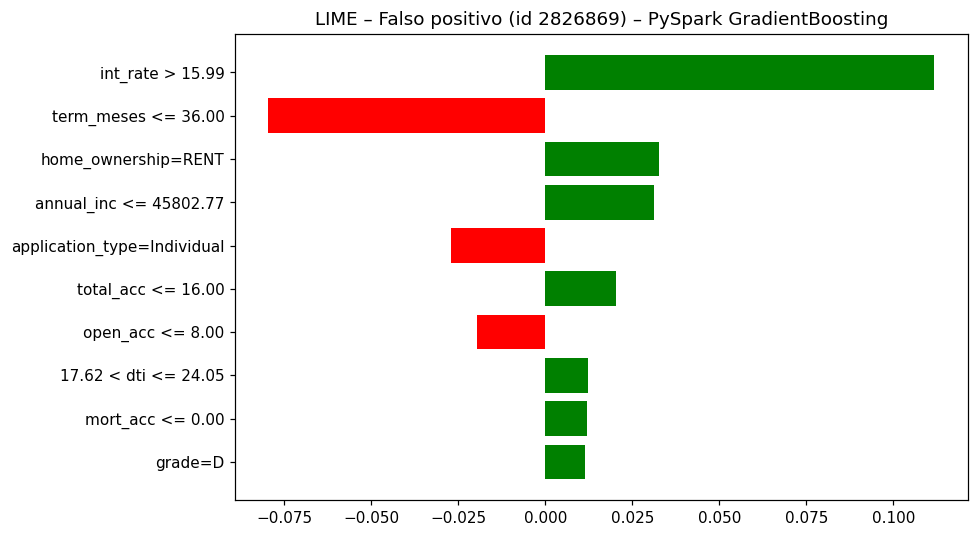

In [6]:
for etiqueta in instancias:  # Figuras exportadas en el notebook 04
    display(Image(filename=str(cfg.DIR_FIGURAS / f"04_lime_{etiqueta.replace(' ', '_')}_pyspark.png")))  # Muestra la figura

## Comparación entre entornos

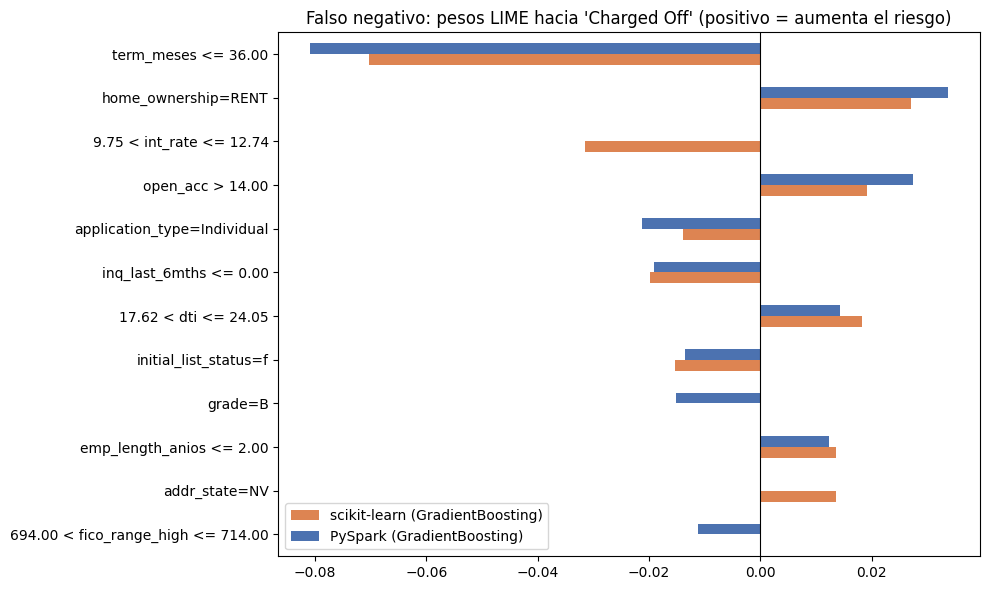

,scikit-learn (GradientBoosting),PySpark (GradientBoosting)
term_meses <= 36.00,-0.070237,-0.080811
home_ownership=RENT,0.026968,0.033717
9.75 < int_rate <= 12.74,-0.031404,NaN
open_acc > 14.00,0.019131,0.027334
application_type=Individual,-0.013917,-0.021223
inq_last_6mths <= 0.00,-0.019780,-0.019138
17.62 < dti <= 24.05,0.018321,0.014213
initial_list_status=f,-0.015412,-0.013503
grade=B,NaN,-0.015096
emp_length_anios <= 2.00,0.013580,0.012334


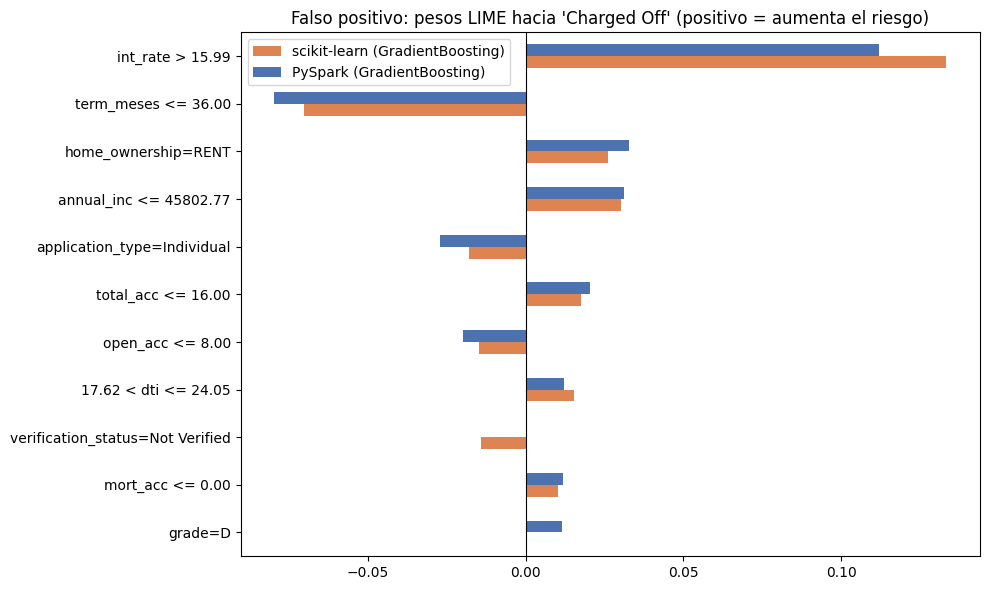

,scikit-learn (GradientBoosting),PySpark (GradientBoosting)
int_rate > 15.99,0.133213,0.111797
term_meses <= 36.00,-0.070213,-0.079549
home_ownership=RENT,0.026093,0.032651
annual_inc <= 45802.77,0.030061,0.031177
application_type=Individual,-0.017898,-0.027006
total_acc <= 16.00,0.017501,0.020318
open_acc <= 8.00,-0.014586,-0.019715
17.62 < dti <= 24.05,0.015199,0.012227
verification_status=Not Verified,-0.014056,NaN
mort_acc <= 0.00,0.010326,0.012013


In [7]:
for etiqueta in instancias:  # Una comparación por instancia
    pesos = pd.DataFrame({  # Pesos por condición en ambos entornos
        f"scikit-learn ({mejor_sk})": dict(explicaciones_sk[etiqueta]["exp"].as_list(label=1)),  # Pesos de scikit-learn
        f"PySpark ({mejor_sp})": dict((c, w) for c, w in lime_sp["explicaciones"][etiqueta]["pesos"]),  # Pesos de PySpark
    })
    pesos = pesos.reindex(pesos.abs().max(axis=1).sort_values().index)  # Ordena por importancia
    ax = pesos.plot.barh(figsize=(10, 6), color=["#DD8452", "#4C72B0"])  # Barras agrupadas
    ax.axvline(0, color="black", lw=0.8)  # Línea en cero
    ax.set_title(f"{etiqueta}: pesos LIME hacia 'Charged Off' (positivo = aumenta el riesgo)")  # Título
    plt.tight_layout(); guardar_figura(ax.figure, f"06_lime_comparacion_{etiqueta.replace(' ', '_')}"); plt.show()  # Exporta y muestra
    display(pesos.iloc[::-1])  # Tabla de pesos (más importante primero)

In [8]:
resumen = pd.DataFrame([  # Probabilidad, ajuste local y costo de cada explicación
    {"instancia": e, "entorno": "scikit-learn", "P(default)": explicaciones_sk[e]["exp"].predict_proba[1],  # scikit-learn
     "R² local": explicaciones_sk[e]["exp"].score, "tiempo (s)": explicaciones_sk[e]["tiempo_s"]} for e in instancias] + [  # Métricas
    {"instancia": e, "entorno": "PySpark", "P(default)": lime_sp["explicaciones"][e]["p_default"],  # PySpark
     "R² local": lime_sp["explicaciones"][e]["r2_local"], "tiempo (s)": lime_sp["explicaciones"][e]["tiempo_s"]} for e in instancias])  # Métricas
print(f"PySpark: {lime_sp['n_llamadas']} llamadas al modelo, {lime_sp['tiempo_medio_llamada_s']:.2f} s por llamada en promedio")  # Costo por llamada
resumen.set_index(["instancia", "entorno"])  # Muestra la tabla

PySpark: 3 llamadas al modelo, 0.57 s por llamada en promedio


,,P(default),R² local,tiempo (s)
instancia,entorno,,,
Falso negativo,scikit-learn,0.156228,0.175248,3.323424
Falso positivo,scikit-learn,0.341288,0.525030,3.272462
Falso negativo,PySpark,0.139924,0.195292,3.845228
Falso positivo,PySpark,0.299095,0.441838,3.756416


## Discusión: qué aporta LIME y sus limitaciones en entornos distribuidos

**Las explicaciones.** En ambos entornos el mejor modelo probabilístico es *gradient
boosting* (AUC 0,7207 / 0,7208).

* **Falso negativo (id 101230150, sí hizo default):** grado B, tasa de 11,49 %, plazo de 36 meses,
  FICO 704 y utilización revolvente del 24 %. Es un perfil de bajo riesgo, y ambos modelos le
  asignan P(default) ≈ 0,14–0,16, por debajo del umbral (≈ 0,21). Según LIME, lo que más reduce el
  riesgo es el **plazo de 36 meses** (−0,07 / −0,08) y la tasa baja; empujan hacia arriba el
  alquiler de vivienda (`RENT`, +0,03), tener muchas líneas abiertas (`open_acc` > 14) y un `dti`
  de 17–24. El préstamo terminó en default por causas que los datos de originación no recogen
  (un evento posterior), así que el error es esperable.
* **Falso positivo (id 2826869, sí pagó):** grado D, tasa de 17,77 %, ingreso de 30 mil, FICO
  679, un registro público y una quiebra. P(default) ≈ 0,30–0,34, por encima del umbral. La
  variable dominante es **`int_rate` > 15,99** (+0,13 / +0,11), seguida del ingreso bajo y el
  alquiler, compensados parcialmente por el plazo de 36 meses.
* **Consistencia entre entornos:** las variables principales y sus signos coinciden en ambos
  modelos, con magnitudes parecidas; solo cambian las variables en las posiciones 9–10 (grado,
  estado, FICO). Esto confirma que los dos *boosting* aprendieron prácticamente la misma función.

**Qué aporta LIME.** Traduce una predicción individual de un modelo de caja negra a unas pocas
reglas legibles ("plazo ≤ 36 meses reduce el riesgo en 7 puntos"), útiles para justificar
decisiones de crédito, detectar dependencias indeseadas (p. ej., por estado de residencia) y
comparar modelos entre entornos, como aquí.

**Limitaciones generales.** (1) Es **local e inestable**: otra semilla o número de
perturbaciones cambia los pesos, sobre todo los pequeños. (2) El R² local es bajo en el falso
negativo (0,18–0,20): el sustituto lineal explica poco del modelo en ese entorno. (3) Perturba
cada variable **de forma independiente**, lo que genera combinaciones irreales (tasa de 6 % con
grado F). (4) La discretización en cuartiles es arbitraria y cambia el significado de los pesos.

**Limitaciones en entornos distribuidos (PySpark).**
1. LIME trabaja **en memoria local**: necesita en el driver un conjunto de entrenamiento para
   calcular cuartiles y frecuencias, lo que choca con la filosofía de no llevar datos al driver.
2. Cada lote de perturbaciones debe **viajar a la JVM**, convertirse en DataFrame, pasar por el
   pipeline y volver. Sin Arrow (incompatible con Java 21 en Spark 3.5), crear el DataFrame
   desde pandas tardaba ≈ 250 s por llamada; escribiendo Parquet se redujo a ≈ 0,6 s, pero
   cada llamada sigue lanzando varios trabajos de Spark. Explicar miles de instancias sería caro.
3. El modelo debe estar **vivo en la sesión**: en Windows sin `winutils` no se pudo guardar, y
   reajustarlo en otra sesión no reproducía exactamente el modelo del `CrossValidator`.
4. La explicación es de un solo préstamo; para una visión global habría que agregar muchas
   explicaciones, lo que multiplica los costos anteriores.